# Lab 4: Data Imputation using an Autoencoder


In this lab, you will build and train an autoencoder to impute (or "fill in") missing data. 

We will be using the
Adult Data Set provided by the UCI Machine Learning Repository [1], available 
at https://archive.ics.uci.edu/ml/datasets/adult.
The data set contains census record files of adults, including their
age, martial status, the type of work they do, and other features. 

Normally, people use this data set to build a supervised classification
model to classify whether a person is a high income earner.
We will not use the dataset for this original intended purpose.

Instead, we will perform the task of imputing (or "filling in") missing values in the dataset. For example,
we may be missing one person's martial status, and another person's age, and
a third person's level of education. Our model will predict the missing features 
based on the information that we do have about each person.

We will use a variation of a denoising autoencoder to solve this data imputation
problem. Our autoencoder will be trained using inputs that have one categorical feature artificially
removed, and the goal of the autoencoder is to correctly reconstruct all features,
including the one removed from the input.

In the process, you are expected to learn to:

1. Clean and process continuous and categorical data for machine learning.
2. Implement an autoencoder that takes continuous and categorical (one-hot) inputs.
3. Tune the hyperparameters of an autoencoder.
4. Use baseline models to help interpret model performance.

[1] Dua, D. and Karra Taniskidou, E. (2017). UCI Machine Learning Repository [http://archive.ics.uci.edu/ml]. Irvine, CA: University of California, School of Information and Computer Science.


### What to submit

Submit a PDF file containing all your code, outputs, and write-up. You can produce a PDF of your Google Colab file by going to File > Print and then save as PDF. The Colab instructions have more information.

Do not submit any other files produced by your code.

Include a link to your colab file in your submission.


## Colab Link

Include a link to your Colab file here. If you would like the TA to look at your
Colab file in case your solutions are cut off, **please make sure that your Colab
file is publicly accessible at the time of submission**.

Colab Link: https://drive.google.com/file/d/1mBUdbjZOb4AW6dhyRyTFgPT-WHRRoUyJ/view?usp=sharing

In [1]:
import csv
import numpy as np
import random
import torch
import torch.utils.data

## Part 0

We will be using a package called `pandas` for this assignment. 

If you are using Colab, `pandas` should already be available.
If you are using your own computer,
installation instructions for `pandas` are available here: 
https://pandas.pydata.org/pandas-docs/stable/install.html

In [5]:
import pandas as pd

# Part 1. Data Cleaning [15 pt]

The adult.data file is available at `https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data`

The function `pd.read_csv` loads the adult.data file into a pandas dataframe.
You can read about the pandas documentation for `pd.read_csv` at
https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.read_csv.html

In [6]:
header = ['age', 'work', 'fnlwgt', 'edu', 'yredu', 'marriage', 'occupation',
 'relationship', 'race', 'sex', 'capgain', 'caploss', 'workhr', 'country']
df = pd.read_csv(
    "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data",
    names=header,
    index_col=False)

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_6092\1831985018.py:3: ParserWarning: Length of header or names does not match length of data. This leads to a loss of data with index_col=False.
  df = pd.read_csv(


In [7]:
df.shape # there are 32561 rows (records) in the data frame, and 14 columns (features)

(32561, 14)

### Part (a) Continuous Features [3 pt]

For each of the columns `["age", "yredu", "capgain", "caploss", "workhr"]`, report the minimum, maximum, and average value across the dataset. 

Then, normalize each of the features `["age", "yredu", "capgain", "caploss", "workhr"]`
so that their values are always between 0 and 1.
Make sure that you are actually modifying the dataframe `df`. 

Like numpy arrays and torch tensors, 
pandas data frames can be sliced. For example, we can
display the first 3 rows of the data frame (3 records) below.

In [ ]:
df[:3] # show the first 3 records

,age,work,fnlwgt,edu,yredu,marriage,occupation,relationship,race,sex,capgain,caploss,workhr,country
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States


Alternatively, we can slice based on column names, 
for example `df["race"]`, `df["hr"]`, or even index multiple columns 
like below.

In [9]:
subdf = df[["age", "yredu", "capgain", "caploss", "workhr"]]
subdf[:3] # show the first 3 records

,age,yredu,capgain,caploss,workhr
0,39,13,2174,0,40
1,50,13,0,0,13
2,38,9,0,0,40


Numpy works nicely with pandas, like below:

In [10]:
np.sum(subdf["caploss"])

np.int64(2842700)

Just like numpy arrays, you can modify
entire columns of data rather than one scalar element at a time.
For example, the code  

`df["age"] = df["age"] + 1` 

would increment everyone's age by 1.

In [21]:
#max, min, and average of the features across the full dataset 
max_age = np.max(df["age"])
print("max age:", max_age)
min_age = np.min(df["age"])
print("min age:", min_age)
average_age = np.mean(df["age"])
print("average age:", average_age)

max_yeredu = np.max(df["yredu"])
print("max years of education:", max_yeredu)    
min_yeredu = np.min(df["yredu"])
print("min years of education:", min_yeredu)    
average_yeredu = np.mean(df["yredu"])
print("average years of education:", average_yeredu)

max_capgain = np.max(df["capgain"])
print("max capital gain:", max_capgain) 
min_capgain = np.min(df["capgain"])
print("min capital gain:", min_capgain)
average_capgain = np.mean(df["capgain"])
print("average capital gain:", average_capgain)

max_caploss = np.max(df["caploss"])
print("max capital loss:", max_caploss)
min_caploss = np.min(df["caploss"])
print("min capital loss:", min_caploss)
average_caploss = np.mean(df["caploss"])
print("average capital loss:", average_caploss)

max_workhr = np.max(df["workhr"])
print("max work hours:", max_workhr)    
min_workhr = np.min(df["workhr"])
print("min work hours:", min_workhr)
average_workhr = np.mean(df["workhr"])
print("average work hours:", average_workhr)

# normalize the features to be in the range [0, 1] in the actual dataset
df["age"] = (df["age"] - min_age) / (max_age - min_age)
df["yredu"] = (df["yredu"] - min_yeredu) / (max_yeredu - min_yeredu)
df["capgain"] = (df["capgain"] - min_capgain) / (max_capgain - min_capgain)
df["caploss"] = (df["caploss"] - min_caploss) / (max_caploss - min_caploss)
df["workhr"] = (df["workhr"] - min_workhr) / (max_workhr - min_workhr)


max age: 90
min age: 17
average age: 38.58164675532078
max years of education: 16
min years of education: 1
average years of education: 10.0806793403151
max capital gain: 99999
min capital gain: 0
average capital gain: 1077.6488437087312
max capital loss: 4356
min capital loss: 0
average capital loss: 87.303829734959
max work hours: 99
min work hours: 1
average work hours: 40.437455852092995


In [ ]:
# seeing if the normalization worked
subdf = df[["age", "yredu", "capgain", "caploss", "workhr"]]
subdf[:3] # show the first 3 records

,age,yredu,capgain,caploss,workhr
0,0.301370,0.800000,0.02174,0.0,0.397959
1,0.452055,0.800000,0.00000,0.0,0.122449
2,0.287671,0.533333,0.00000,0.0,0.397959


### Part (b) Categorical Features [1 pt]

What percentage of people in our data set are male? Note that the data labels all have an unfortunate space in the beginning, e.g. " Male" instead of "Male".

What percentage of people in our data set are female?

In [29]:
# hint: you can do something like this in pandas
sum(df["sex"] == " Male")

sex = df["sex"]
sex[:3] # show the first 3 records

0     Male
1     Male
2     Male
Name: sex, dtype: str

In [28]:
percentage_female = sum(df["sex"] == " Female") / df.shape[0]
print("percentage of females:", percentage_female*100, "%")

percentage_male = sum(df["sex"] == " Male") / df.shape[0]
print("percentage of males:", percentage_male*100, "%")

percentage of females: 33.07945087681583 %
percentage of males: 66.92054912318419 %


### Part (c) [2 pt]

Before proceeding, we will modify our data frame in a couple more ways:

1. We will restrict ourselves to using a subset of the features (to simplify our autoencoder)
2. We will remove any records (rows) already containing missing values, and store them in a second dataframe. We will only use records without missing values to train our autoencoder.

Both of these steps are done for you, below.

How many records contained missing features? What percentage of records were removed?

In [30]:
contcols = ["age", "yredu", "capgain", "caploss", "workhr"]
catcols = ["work", "marriage", "occupation", "edu", "relationship", "sex"]
features = contcols + catcols
df = df[features]

In [31]:
missing = pd.concat([df[c] == " ?" for c in catcols], axis=1).any(axis=1)
df_with_missing = df[missing]
df_not_missing = df[~missing]

In [32]:
# how many records have missing values?
print("number of records with missing values:", df_with_missing.shape[0])

# what percentage of records were removed 
percentage_removed = df_with_missing.shape[0] / df.shape[0]
print("percentage of records removed:", percentage_removed*100, "%")

number of records with missing values: 1843
percentage of records removed: 5.660145572924664 %


### Part (d) One-Hot Encoding [1 pt]

What are all the possible values of the feature "work" in `df_not_missing`? You may find the Python function `set` useful.

In [34]:
set(df_not_missing["work"])

{' Federal-gov',
 ' Local-gov',
 ' Private',
 ' Self-emp-inc',
 ' Self-emp-not-inc',
 ' State-gov',
 ' Without-pay'}

We will be using a one-hot encoding to represent each of the categorical variables.
Our autoencoder will be trained using these one-hot encodings.

We will use the pandas function `get_dummies` to produce one-hot encodings
for all of the categorical variables in `df_not_missing`. 

In [35]:
data = pd.get_dummies(df_not_missing)

In [36]:
data[:3]

,age,yredu,capgain,caploss,workhr,work_ Federal-gov,work_ Local-gov,work_ Private,work_ Self-emp-inc,work_ Self-emp-not-inc,...,edu_ Prof-school,edu_ Some-college,relationship_ Husband,relationship_ Not-in-family,relationship_ Other-relative,relationship_ Own-child,relationship_ Unmarried,relationship_ Wife,sex_ Female,sex_ Male
0,0.301370,0.800000,0.02174,0.0,0.397959,False,False,False,False,False,...,False,False,False,True,False,False,False,False,False,True
1,0.452055,0.800000,0.00000,0.0,0.122449,False,False,False,False,True,...,False,False,True,False,False,False,False,False,False,True
2,0.287671,0.533333,0.00000,0.0,0.397959,False,False,True,False,False,...,False,False,False,True,False,False,False,False,False,True


### Part (e) One-Hot Encoding [2 pt]

The dataframe `data` contains the cleaned and normalized data that we will use to train our denoising autoencoder.

How many **columns** (features) are in the dataframe `data`?

Briefly explain where that number come from.

In [39]:
# column number of data 
data.shape[1]

57

The dataframe data has 57 columns (features)

We kept 11 features: 5 continuous and 6 categorical. Each continuous feature stays as 1 column. get_dummies replaces each categorical feature with one binary column per possible value, giving 7 (work) + 7 (marriage) + 14 (occupation) + 16 (edu) + 6 (relationship) + 2 (sex) = 52 columns. The total is 5 + 52 = 57.

### Part (f) One-Hot Conversion [3 pt]

We will convert the pandas data frame `data` into numpy, so that
it can be further converted into a PyTorch tensor.
However, in doing so, we lose the column label information that
a panda data frame automatically stores.

Complete the function `get_categorical_value` that will return
the named value of a feature given a one-hot embedding.
You may find the global variables `cat_index` and `cat_values`
useful. (Display them and figure out what they are first.)

We will need this function in the next part of the lab
to interpret our autoencoder outputs. So, the input
to our function `get_categorical_values` might not 
actually be "one-hot" -- the input may instead 
contain real-valued predictions from our neural network.

In [40]:
datanp = data.values.astype(np.float32)

In [45]:
cat_index = {}  # Mapping of feature -> start index of feature in a record
cat_values = {} # Mapping of feature -> list of categorical values the feature can take

# build up the cat_index and cat_values dictionary
for i, header in enumerate(data.keys()):
    if "_" in header: # categorical header
        feature, value = header.split()
        feature = feature[:-1] # remove the last char; it is always an underscore
        if feature not in cat_index:
            cat_index[feature] = i
            cat_values[feature] = [value]
        else:
            cat_values[feature].append(value)

def get_onehot(record, feature):
    """
    Return the portion of `record` that is the one-hot encoding
    of `feature`. For example, since the feature "work" is stored
    in the indices [5:12] in each record, calling `get_range(record, "work")`
    is equivalent to accessing `record[5:12]`.
    
    Args:
        - record: a numpy array representing one record, formatted
                  the same way as a row in `data.np`
        - feature: a string, should be an element of `catcols`
    """
    start_index = cat_index[feature]
    stop_index = cat_index[feature] + len(cat_values[feature])
    return record[start_index:stop_index]

def get_categorical_value(onehot, feature):
    """
    Return the categorical value name of a feature given
    a one-hot vector representing the feature.
    
    Args:
        - onehot: a numpy array one-hot representation of the feature
        - feature: a string, should be an element of `catcols`
        
    Examples:
    
    >>> get_categorical_value(np.array([0., 0., 0., 0., 0., 1., 0.]), "work")
    'State-gov'
    >>> get_categorical_value(np.array([0.1, 0., 1.1, 0.2, 0., 1., 0.]), "work")
    'Private'
    """
    # <----- TODO: WRITE YOUR CODE HERE ----->
    # You may find the variables `cat_index` and `cat_values` 
    # (created above) useful.
    index = np.argmax(onehot)
    return cat_values[feature][index]

print("cat_index:", cat_index)
print("cat_values:", cat_values)
print(get_categorical_value(np.array([0., 0., 0., 0., 0., 1., 0.]), "work"))      # State-gov
print(get_categorical_value(np.array([0.1, 0., 1.1, 0.2, 0., 1., 0.]), "work"))   # Private

cat_index: {'work': 5, 'marriage': 12, 'occupation': 19, 'edu': 33, 'relationship': 49, 'sex': 55}
cat_values: {'work': ['Federal-gov', 'Local-gov', 'Private', 'Self-emp-inc', 'Self-emp-not-inc', 'State-gov', 'Without-pay'], 'marriage': ['Divorced', 'Married-AF-spouse', 'Married-civ-spouse', 'Married-spouse-absent', 'Never-married', 'Separated', 'Widowed'], 'occupation': ['Adm-clerical', 'Armed-Forces', 'Craft-repair', 'Exec-managerial', 'Farming-fishing', 'Handlers-cleaners', 'Machine-op-inspct', 'Other-service', 'Priv-house-serv', 'Prof-specialty', 'Protective-serv', 'Sales', 'Tech-support', 'Transport-moving'], 'edu': ['10th', '11th', '12th', '1st-4th', '5th-6th', '7th-8th', '9th', 'Assoc-acdm', 'Assoc-voc', 'Bachelors', 'Doctorate', 'HS-grad', 'Masters', 'Preschool', 'Prof-school', 'Some-college'], 'relationship': ['Husband', 'Not-in-family', 'Other-relative', 'Own-child', 'Unmarried', 'Wife'], 'sex': ['Female', 'Male']}
State-gov
Private


In [46]:
# more useful code, used during training, that depends on the function
# you write above

def get_feature(record, feature):
    """
    Return the categorical feature value of a record
    """
    onehot = get_onehot(record, feature)
    return get_categorical_value(onehot, feature)

def get_features(record):
    """
    Return a dictionary of all categorical feature values of a record
    """
    return { f: get_feature(record, f) for f in catcols }

### Part (g) Train/Test Split [3 pt]

Randomly split the data into approximately 70% training, 15% validation and 15% test.

Report the number of items in your training, validation, and test set.

In [ ]:
# set the numpy seed for reproducibility
# https://docs.scipy.org/doc/numpy/reference/generated/numpy.random.seed.html
np.random.seed(50)

n = datanp.shape[0]
indices = np.random.permutation(n)   # every row position exactly once, in random order

train_end = int(0.70 * n)
valid_end = int(0.85 * n)

train_idx = indices[:train_end]
valid_idx = indices[train_end:valid_end]
test_idx  = indices[valid_end:]

data_train = datanp[train_idx]
data_valid = datanp[valid_idx]
data_test  = datanp[test_idx]

print("train:", len(data_train))
print("valid:", len(data_valid))
print("test:", len(data_test))

train: 21502
valid: 4608
test: 4608


## Part 2. Model Setup [5 pt]

### Part (a) [4 pt]

Design a fully-connected autoencoder by modifying the `encoder` and `decoder`
below.

The input to this autoencoder will be the features of the `data`, with
one categorical feature recorded as "missing". The output of the autoencoder
should be the reconstruction of the same features, but with the missing
value filled in.

**Note**: Do not reduce the dimensionality of the input too much!
The output of your embedding is expected to contain information 
about ~11 features.

In [56]:
from torch import nn

class AutoEncoder(nn.Module):
    def __init__(self, hidden=40, bottleneck=24):
        super(AutoEncoder, self).__init__()
        self.encoder = nn.Sequential(
            nn.Linear(57, hidden),
            nn.ReLU(),
            nn.Linear(hidden, bottleneck),
            nn.ReLU()
        )
        self.decoder = nn.Sequential(
            nn.Linear(bottleneck, hidden),
            nn.ReLU(),
            nn.Linear(hidden, 57),
            nn.Sigmoid() # get to the range (0, 1)
        )

    def forward(self, x):
        x = self.encoder(x)
        x = self.decoder(x)
        return x


In [ ]:
# Testing if it will run 
model = AutoEncoder()
out = model(torch.tensor(datanp[:3]))
print(out.shape)  # should be torch.Size([3, 57])

torch.Size([3, 57])


### Part (b) [1 pt]

Explain why there is a sigmoid activation in the last step of the decoder.

(**Note**: the values inside the data frame `data` and the training code in Part 3 might be helpful.)

Every value in data lies between 0 and 1, since the continuous features were min-max normalized and the categorical features are one-hot encoded. The training code compares the reconstruction directly to these values using MSE loss. The sigmoid squashes each output into (0, 1), matching the range of the targets. Without it, the final linear layer could produce any real number, including values that are impossible for this data.

## Part 3. Training [18] 

### Part (a) [6 pt]

We will train our autoencoder in the following way:

- In each iteration, we will hide one of the categorical features using the `zero_out_random_features` function
- We will pass the data with one missing feature through the autoencoder, and obtain a reconstruction
- We will check how close the reconstruction is compared to the original data -- including the value of the missing feature

Complete the code to train the autoencoder, and plot the training and validation loss every few iterations.
You may also want to plot training and validation "accuracy" every few iterations, as we will define in
part (b). You may also want to checkpoint your model every few iterations or epochs.

Use `nn.MSELoss()` as your loss function. (Side note: you might recognize that this loss function is not
ideal for this problem, but we will use it anyway.)

In [52]:
import matplotlib.pyplot as plt

def zero_out_feature(records, feature):
    """ Set the feature missing in records, by setting the appropriate
    columns of records to 0
    """
    start_index = cat_index[feature]
    stop_index = cat_index[feature] + len(cat_values[feature])
    records[:, start_index:stop_index] = 0
    return records

def zero_out_random_feature(records):
    """ Set one random feature missing in records, by setting the 
    appropriate columns of records to 0
    """
    return zero_out_feature(records, random.choice(catcols))

def get_loss(model, loader, criterion):
    """Average reconstruction loss, with one random feature hidden per batch."""
    total, count = 0.0, 0
    with torch.no_grad():
        for batch in loader:
            recon = model(zero_out_random_feature(batch.clone()))
            total += criterion(recon, batch).item() * len(batch)
            count += len(batch)
    return total / count

def train(model, train_loader, valid_loader, num_epochs=5, learning_rate=1e-4, eval_every=50, name="model"):
    """ Training loop. You should update this."""
    torch.manual_seed(42)
    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

    iters, train_loss, valid_loss, train_acc, valid_acc = [], [], [], [], []
    iteration = 0

    for epoch in range(num_epochs):
        for data in train_loader:
            datam = zero_out_random_feature(data.clone()) # zero out one categorical feature
            recon = model(datam)
            loss = criterion(recon, data)
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()
            iteration += 1

            if iteration % eval_every == 0:
                iters.append(iteration)
                train_loss.append(get_loss(model, train_loader, criterion))
                valid_loss.append(get_loss(model, valid_loader, criterion))
                train_acc.append(get_accuracy(model, train_loader))
                valid_acc.append(get_accuracy(model, valid_loader))

        torch.save(model.state_dict(), f"{name}_epoch{epoch}.pt")
        if valid_acc:
            print(f"Epoch {epoch}: val loss {valid_loss[-1]:.4f}, val acc {valid_acc[-1]:.4f}")

    plt.plot(iters, train_loss, label="Train")
    plt.plot(iters, valid_loss, label="Validation")
    plt.title("Loss"); plt.xlabel("Iteration"); plt.ylabel("MSE loss"); plt.legend(); plt.show()

    plt.plot(iters, train_acc, label="Train")
    plt.plot(iters, valid_acc, label="Validation")
    plt.title("Accuracy"); plt.xlabel("Iteration"); plt.ylabel("Accuracy"); plt.legend(); plt.show()
            

### Part (b) [3 pt]

While plotting training and validation loss is valuable, loss values are harder to compare
than accuracy percentages. It would be nice to have a measure of "accuracy" in this problem.

Since we will only be imputing missing categorical values, we will define an accuracy measure.
For each record and for each categorical feature, we determine whether
the model can predict the categorical feature given all the other features of the record.

A function `get_accuracy` is written for you. It is up to you to figure out how to
use the function. **You don't need to submit anything in this part.**
To earn the marks, correctly plot the training and validation accuracy every few 
iterations as part of your training curve.

In [53]:
def get_accuracy(model, data_loader):
    """Return the "accuracy" of the autoencoder model across a data set.
    That is, for each record and for each categorical feature, 
    we determine whether the model can successfully predict the value
    of the categorical feature given all the other features of the 
    record. The returned "accuracy" measure is the percentage of times 
    that our model is successful.
        
    Args:
       - model: the autoencoder model, an instance of nn.Module
       - data_loader: an instance of torch.utils.data.DataLoader

    Example (to illustrate how get_accuracy is intended to be called.
             Depending on your variable naming this code might require
             modification.)

        >>> model = AutoEncoder()
        >>> vdl = torch.utils.data.DataLoader(data_valid, batch_size=256, shuffle=True)
        >>> get_accuracy(model, vdl)
    """
    total = 0
    acc = 0
    for col in catcols:
        for item in data_loader: # minibatches
            inp = item.detach().numpy()
            out = model(zero_out_feature(item.clone(), col)).detach().numpy()
            for i in range(out.shape[0]): # record in minibatch
                acc += int(get_feature(out[i], col) == get_feature(inp[i], col))
                total += 1
    return acc / total

### Part (c) [4 pt]

Run your updated training code, using reasonable initial hyperparameters.

Include your training curve in your submission.

Epoch 0: val loss 0.1255, val acc 0.3867
Epoch 1: val loss 0.0678, val acc 0.4626
Epoch 2: val loss 0.0554, val acc 0.5512
Epoch 3: val loss 0.0538, val acc 0.5569
Epoch 4: val loss 0.0480, val acc 0.5693
Epoch 5: val loss 0.0435, val acc 0.5849
Epoch 6: val loss 0.0412, val acc 0.5839
Epoch 7: val loss 0.0373, val acc 0.5900
Epoch 8: val loss 0.0319, val acc 0.5995
Epoch 9: val loss 0.0295, val acc 0.5974
Epoch 10: val loss 0.0264, val acc 0.6063
Epoch 11: val loss 0.0253, val acc 0.6103
Epoch 12: val loss 0.0237, val acc 0.6100
Epoch 13: val loss 0.0225, val acc 0.6109
Epoch 14: val loss 0.0228, val acc 0.6145
Epoch 15: val loss 0.0217, val acc 0.6171
Epoch 16: val loss 0.0216, val acc 0.6160
Epoch 17: val loss 0.0198, val acc 0.6166
Epoch 18: val loss 0.0217, val acc 0.6244
Epoch 19: val loss 0.0194, val acc 0.6189
Epoch 20: val loss 0.0204, val acc 0.6203
Epoch 21: val loss 0.0196, val acc 0.6190
Epoch 22: val loss 0.0192, val acc 0.6188
Epoch 23: val loss 0.0183, val acc 0.6179
Ep

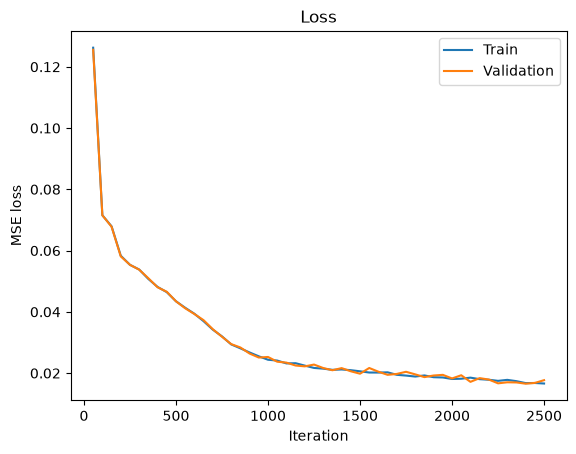

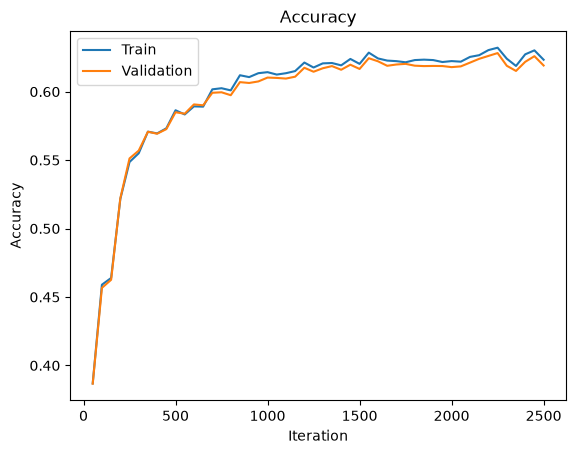

In [54]:
random.seed(42)   # zero_out_random_feature uses Python's random module

train_loader = torch.utils.data.DataLoader(data_train, batch_size=256, shuffle=True)
valid_loader = torch.utils.data.DataLoader(data_valid, batch_size=256, shuffle=False)

model = AutoEncoder()
train(model, train_loader, valid_loader, num_epochs=30, learning_rate=1e-3,
      eval_every=50, name="base")


### Part (d) [5 pt]

Tune your hyperparameters, training at least 4 different models (4 sets of hyperparameters).

Do not include all your training curves. Instead, explain what hyperparameters
you tried, what their effect was, and what your thought process was as you 
chose the next set of hyperparameters to try.

In [ ]:
random.seed(42)

train_loader = torch.utils.data.DataLoader(data_train, batch_size=256, shuffle=True)
valid_loader = torch.utils.data.DataLoader(data_valid, batch_size=256, shuffle=False)

model2 = AutoEncoder(hidden=64, bottleneck=32)
train(model2, train_loader, valid_loader, num_epochs=30, learning_rate=1e-3,
      eval_every=50, name="model2")

Epoch 0: val loss 0.0745, val acc 0.4570
Epoch 1: val loss 0.0576, val acc 0.5371
Epoch 2: val loss 0.0508, val acc 0.5592
Epoch 3: val loss 0.0476, val acc 0.5634
Epoch 4: val loss 0.0393, val acc 0.5846
Epoch 5: val loss 0.0313, val acc 0.6049
Epoch 6: val loss 0.0291, val acc 0.6066
Epoch 7: val loss 0.0265, val acc 0.6066
Epoch 8: val loss 0.0238, val acc 0.6131
Epoch 9: val loss 0.0224, val acc 0.6090
Epoch 10: val loss 0.0211, val acc 0.6115
Epoch 11: val loss 0.0204, val acc 0.6151
Epoch 12: val loss 0.0187, val acc 0.6151
Epoch 13: val loss 0.0178, val acc 0.6192
Epoch 14: val loss 0.0184, val acc 0.6228
Epoch 15: val loss 0.0168, val acc 0.6225
Epoch 16: val loss 0.0168, val acc 0.6264
Epoch 17: val loss 0.0151, val acc 0.6231
Epoch 18: val loss 0.0171, val acc 0.6294
Epoch 19: val loss 0.0143, val acc 0.6321
Epoch 20: val loss 0.0158, val acc 0.6321
Epoch 21: val loss 0.0146, val acc 0.6273
Epoch 22: val loss 0.0145, val acc 0.6303
Epoch 23: val loss 0.0134, val acc 0.6331
Ep

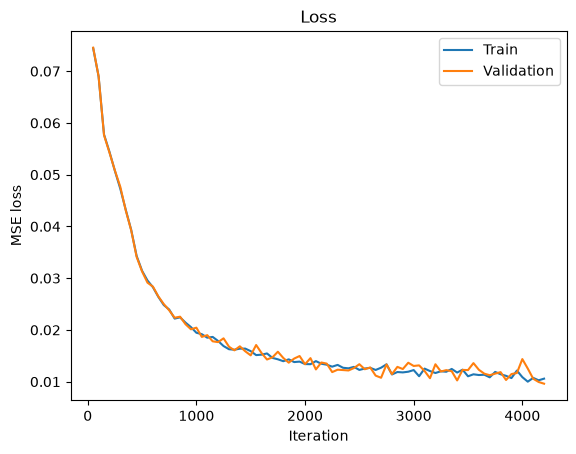

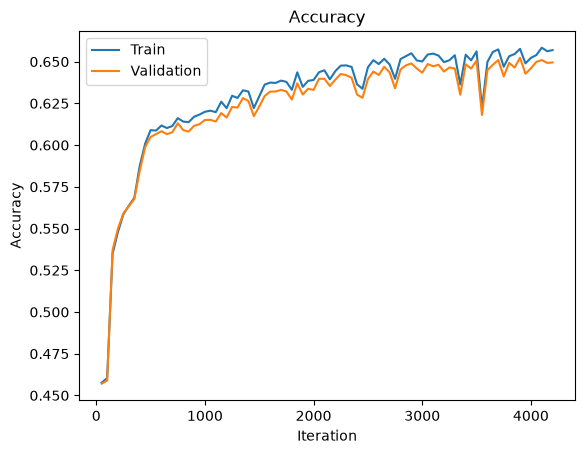

In [58]:
random.seed(42)

train_loader = torch.utils.data.DataLoader(data_train, batch_size=256, shuffle=True)
valid_loader = torch.utils.data.DataLoader(data_valid, batch_size=256, shuffle=False)

model3 = AutoEncoder(hidden=64, bottleneck=32)
train(model3, train_loader, valid_loader, num_epochs=50, learning_rate=1e-3,
      eval_every=50, name="model3")

Epoch 0: val loss 0.0732, val acc 0.4567
Epoch 1: val loss 0.0533, val acc 0.5597
Epoch 2: val loss 0.0389, val acc 0.5904
Epoch 3: val loss 0.0349, val acc 0.6001
Epoch 4: val loss 0.0293, val acc 0.6104
Epoch 5: val loss 0.0260, val acc 0.6148
Epoch 6: val loss 0.0245, val acc 0.6155
Epoch 7: val loss 0.0224, val acc 0.6187
Epoch 8: val loss 0.0200, val acc 0.6198
Epoch 9: val loss 0.0181, val acc 0.6259
Epoch 10: val loss 0.0169, val acc 0.6234
Epoch 11: val loss 0.0171, val acc 0.6294
Epoch 12: val loss 0.0151, val acc 0.6291
Epoch 13: val loss 0.0145, val acc 0.6290
Epoch 14: val loss 0.0155, val acc 0.6343
Epoch 15: val loss 0.0134, val acc 0.6311
Epoch 16: val loss 0.0140, val acc 0.6293
Epoch 17: val loss 0.0120, val acc 0.6250
Epoch 18: val loss 0.0144, val acc 0.6413
Epoch 19: val loss 0.0115, val acc 0.6410
Epoch 20: val loss 0.0132, val acc 0.6359
Epoch 21: val loss 0.0118, val acc 0.6407
Epoch 22: val loss 0.0115, val acc 0.6342
Epoch 23: val loss 0.0106, val acc 0.6448
Ep

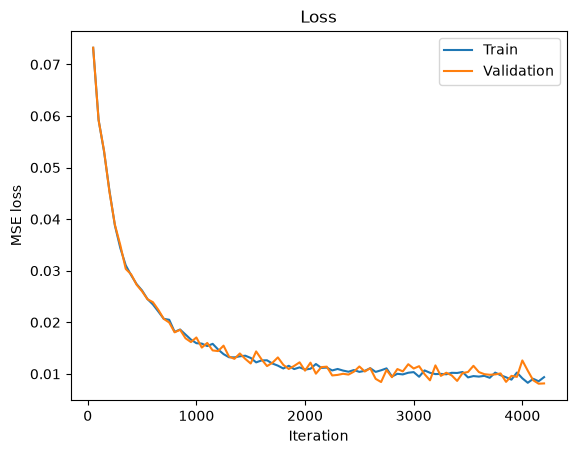

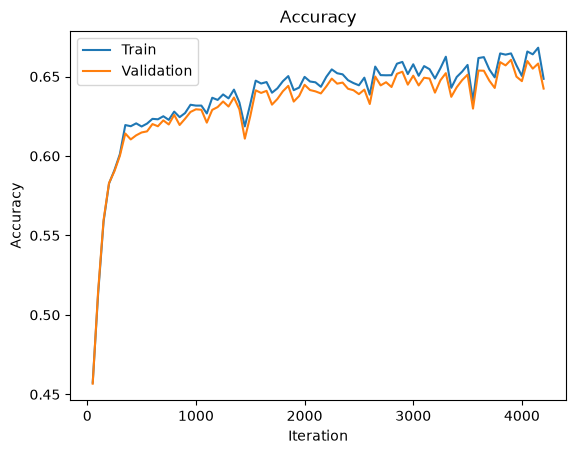

In [59]:
random.seed(42)

train_loader = torch.utils.data.DataLoader(data_train, batch_size=256, shuffle=True)
valid_loader = torch.utils.data.DataLoader(data_valid, batch_size=256, shuffle=False)

model4 = AutoEncoder(hidden=128, bottleneck=48)
train(model4, train_loader, valid_loader, num_epochs=50, learning_rate=1e-3,
      eval_every=50, name="model4")

Model 1 (baseline, Part 3c): architecture 57 → 40 → 24 → 40 → 57 with ReLU, learning rate 0.001, batch size 256, 30 epochs.

- Validation accuracy rose quickly to about 60% by epoch 8, then levelled off at about 62%. It averaged 62.2% over the last 5 epochs, with a best of 62.8%.
- The training and validation curves (loss and accuracy) stayed almost on top of each other the whole time, so there was no sign of overfitting.
- Since accuracy had levelled off without overfitting, the model seemed limited by its capacity rather than by training time or memorization. A 24-unit bottleneck may be too narrow to store 11 features, some of which have up to 16 categories. Therefore, the model size was increased next, with all other hyperparameters unchanged.

Model 2 (larger network): architecture 57 → 64 → 32 → 64 → 57; learning rate, batch size and epochs unchanged.

- Validation accuracy improved to 63.8% averaged over the last 5 epochs, with a best of 64.3%, about 1.6 percentage points higher than Model 1. The final validation loss was also lower (about 0.013 vs. 0.018).
- Unlike Model 1, accuracy was still slowly rising and loss was still falling at epoch 30, so the model had not finished learning.
- A small gap (under 1%) opened between training and validation accuracy late in training. This is a mild sign the model is starting to fit the training data more closely, but it is not yet a problem.
- The larger model helped, which confirms capacity was a limit. Because its curves were still improving at the end, the same architecture was next trained for longer, while monitoring whether the train/validation gap grew.

Model 3 (longer training): same as Model 2, but 50 epochs.

- Thanks to the fixed seeds, the first 30 epochs matched Model 2 exactly, so the difference comes only from the extra training.
- Validation accuracy reached 64.9% averaged over the last 5 epochs (best 65.2% at epoch 46), about 1.1 points above Model 2. Most of the gain came between epochs 30 and 40, and accuracy then levelled off around 65%.
- The train/validation gap stayed small and stable (about 0.7%), so the extra epochs did not cause meaningful overfitting. There were a few brief dips in accuracy (for example, near iteration 3550), but the model recovered immediately each time.
- Longer training gave diminishing returns, and the model still was not overfitting. The bigger model had given the largest improvement so far, so capacity was increased further next, keeping 50 epochs.

Model 4 (larger network again): 57 → 128 → 48 → 128 → 57, learning rate 0.001, batch size 256, 50 epochs.

- Model 4 learned faster: it passed 64% validation accuracy by epoch 19, compared with about epoch 24 for Model 3.
- Its final performance was only slightly better. It averaged 65.2% over the last 5 epochs (vs. 64.9% for Model 3), with a best of 66.1% at epoch 46. This 0.3-point difference is within the ±0.5% epoch-to-epoch noise, so the larger model gives at most a small improvement.
- The train/validation gap grew slightly, from about 0.7% to about 1%, and accuracy fluctuated more, with dips to about 63% at epochs 30 and 39. The extra capacity is starting to fit the training data more closely without improving generalization much, an early sign of overfitting.
- Conclusion: returns from more capacity are diminishing. Going from Model 1 to Model 2 gained 1.6 points, but going from Model 3 to Model 4 gained only 0.3. Further increases in size would likely lead to overfitting rather than better accuracy

Final choice: Model 4 achieved the highest validation accuracy, so its checkpoint from epoch 46 (66.1% validation accuracy) was selected for testing in Part 4. Since validation accuracy varied by up to about 1.8% between nearby epochs, this saved checkpoint was used instead of the final-epoch weights, which reached only 64.2%.

## Part 4. Testing [12 pt]

### Part (a) [2 pt]

Compute and report the test accuracy.

In [60]:
test_loader = torch.utils.data.DataLoader(data_test, batch_size=256, shuffle=False)

best_model = AutoEncoder(hidden=128, bottleneck=48)
best_model.load_state_dict(torch.load("model4_epoch46.pt"))

test_acc = get_accuracy(best_model, test_loader)
print("Test accuracy:", test_acc * 100, "%")


Test accuracy: 65.38990162037037 %


Test Accuracy is 65.4%

### Part (b) [4 pt]

Based on the test accuracy alone, it is difficult to assess whether our model
is actually performing well. We don't know whether a high accuracy is due to
the simplicity of the problem, or if a poor accuracy is a result of the inherent
difficulty of the problem.

It is therefore very important to be able to compare our model to at least one
alternative. In particular, we consider a simple **baseline**
model that is not very computationally expensive. Our neural network
should at least outperform this baseline model. If our network is not much
better than the baseline, then it is not doing well.

For our data imputation problem, consider the following baseline model:
to predict a missing feature, the baseline model will look at the **most common value** of the feature in the training set. 

For example, if the feature "marriage" is missing, then this model's prediction will be the most common value for "marriage" in the training set, which happens to be "Married-civ-spouse".

What would be the test accuracy of this baseline model?


In [61]:
from collections import Counter

correct, total = 0, 0
for col in catcols:
    # most common value of this feature in the training set
    most_common = Counter(get_feature(r, col) for r in data_train).most_common(1)[0][0]
    # predict that value for every test record
    col_correct = sum(get_feature(r, col) == most_common for r in data_test)
    print(f"{col}: predicts '{most_common}', test accuracy {col_correct / len(data_test):.4f}")
    correct += col_correct
    total += len(data_test)

print("Baseline test accuracy:", correct / total * 100, "%")

work: predicts 'Private', test accuracy 0.7426
marriage: predicts 'Married-civ-spouse', test accuracy 0.4622
occupation: predicts 'Prof-specialty', test accuracy 0.1315
edu: predicts 'HS-grad', test accuracy 0.3238
relationship: predicts 'Husband', test accuracy 0.4106
sex: predicts 'Male', test accuracy 0.6704
Baseline test accuracy: 45.68504050925926 %


The baseline model predicts the most common training-set value for each missing feature: "Private" for work, "Married-civ-spouse" for marriage, "Prof-specialty" for occupation, "HS-grad" for edu, "Husband" for relationship and "Male" for sex. Its test accuracy is 45.7%. The baseline performs well on features dominated by one value, such as work (74.3%) and sex (67.0%), but poorly on features spread across many categories, such as occupation (13.2%) and edu (32.4%).

### Part (c) [1 pt]

How does your test accuracy from part (a) compared to your basline test accuracy in part (b)?

The autoencoder's test accuracy (65.4%) is 19.7 percentage points higher than the baseline's test accuracy (45.7%), about 1.4 times the baseline. Since the baseline ignores each record's other features and always predicts the most common value, this gap shows that the autoencoder has learned meaningful relationships between features, such as between relationship, sex and marriage, and uses them to impute missing values. The model therefore performs considerably better than this simple alternative.

### Part (d) [1 pt]

Look at the first item in your test data. 
Do you think it is reasonable for a human
to be able to guess this person's education level
based on their other features? Explain.

In [62]:
first = data_test[0]
print(get_features(first))
print("age:", first[0] * (max_age - min_age) + min_age)
print("yredu:", first[1] * (max_yeredu - min_yeredu) + min_yeredu)
print("capgain:", first[2] * (max_capgain - min_capgain) + min_capgain)
print("caploss:", first[3] * (max_caploss - min_caploss) + min_caploss)
print("workhr:", first[4] * (max_workhr - min_workhr) + min_workhr)


{'work': 'Private', 'marriage': 'Divorced', 'occupation': 'Prof-specialty', 'edu': 'Bachelors', 'relationship': 'Not-in-family', 'sex': 'Male'}
age: 64.99999964237213
yredu: 13.000000178813934
capgain: 6722.999933749437
caploss: 0.0
workhr: 39.999998927116394


The first test record describes a 65-year-old divorced male working in the private sector in a professional specialty occupation, with 13 years of education, a capital gain of $6,723 and a 40-hour work week. His true education level is Bachelors.

It is reasonable for a human to guess this person's education level. In this dataset, years of education ("yredu") corresponds directly to the education category, and 13 years corresponds to a Bachelors degree. The other features support this guess: a professional specialty occupation usually requires post-secondary education, and the capital gain suggests above-average income. Even without the "yredu" feature, a human could narrow the education level down to a few likely options, such as Bachelors or Some-college, but "yredu" makes the guess straightforward.

### Part (e) [2 pt]

What is your model's prediction of this person's education
level, given their other features?


In [63]:
first = torch.tensor(data_test[0:1])               # first test record, as a batch of 1
first_masked = zero_out_feature(first.clone(), "edu")  # hide the education level

out = best_model(first_masked).detach().numpy()[0]
print("Model's prediction:", get_feature(out, "edu"))
print("True value:", get_feature(data_test[0], "edu"))

Model's prediction: Masters
True value: Bachelors


Given the person's other features, the model predicts an education level of Masters. The true education level is Bachelors, so this prediction is incorrect. However, Bachelors received the second-highest output (0.098 vs. 0.109 for Masters), which shows that the model narrowed the prediction to closely related, higher-education categories. This is consistent with the person's professional specialty occupation, even though the model did not fully use the "yredu" value of 13 years, which corresponds exactly to Bachelors.

### Part (f) [2 pt]

What is the baseline model's prediction
of this person's education level?

In [64]:
baseline_edu = Counter(get_feature(r, "edu") for r in data_train).most_common(1)[0][0]
print("Baseline prediction:", baseline_edu)
print("True value:", get_feature(data_test[0], "edu"))

Baseline prediction: HS-grad
True value: Bachelors


The baseline model predicts HS-grad, the most common education level in the training set. It ignores all of the person's other features, so it makes this prediction for every record. The prediction is incorrect, since the person's true education level is Bachelors. It is also further from the true value than the autoencoder's prediction (Masters), because the baseline has no way to use the professional occupation or 13 years of education that point towards a university degree.